# 🧠 Aprendizado por Reforço — do Q-Learning Tabular a um Agente de Trading com Dados Reais

**Aula prática (≈ 3h) | Nível avançado**

| Bloco | Conteúdo | Tempo |
|---|---|---|
| 1 | Fundamentos: agentes, recompensas, Bellman, Q-Learning, exploração vs explotação | 40 min |
| 2 | Laboratório 1: Q-Learning tabular no FrozenLake (Gymnasium) | 50 min |
| 3 | Laboratório 2: agente de trading com dados reais de mercado (yfinance) | 70 min |
| 4 | Discussão e exercícios: limitações, DQN e conexão com sistemas de recomendação | 20 min |

> 💡 Repare nas células de **markdown dinâmico**: relatórios gerados por código com as métricas
> calculadas em tempo de execução — quando os dados mudam e você reexecuta, a análise se atualiza sozinha.

In [1]:
# ============================================================
# IMPORTS GLOBAIS E REPRODUTIBILIDADE
# ============================================================
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf          # DADOS REAIS da internet (Yahoo Finance)
import gymnasium as gym
from gymnasium import spaces
from IPython.display import Markdown, display   # MARKDOWN DINÂMICO

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

import warnings

# 1) Se a classe Pandas4Warning existir nesta versão do pandas, silencia tudo dela
try:
    from pandas.errors import Pandas4Warning
    warnings.filterwarnings("ignore", category=Pandas4Warning)
except ImportError:
    pass  # versão antiga do pandas: a classe ainda não existe, nada a fazer

# 2) Rede de segurança: silencia FutureWarning vindo do módulo do yfinance

print(f"gymnasium {gym.__version__} | pandas {pd.__version__} | numpy {np.__version__}")

gymnasium 1.4.0 | pandas 3.1.1 | numpy 2.4.6


## 1. Fundamentos

### 1.1 O que é Aprendizado por Reforço?

Aprendizado por Reforço (RL) é o paradigma em que um **agente** aprende por **tentativa e erro**, interagindo com um **ambiente**. Não existe "resposta certa" por exemplo (como no aprendizado supervisionado): existe apenas um **sinal de recompensa** — às vezes raro e atrasado — e o agente precisa descobrir sozinho **qual sequência de decisões maximiza o ganho acumulado no longo prazo**.

**Exemplos reais:**
- 🤖 um robô aprendendo a andar (recompensa = distância sem cair)
- ♟️ um agente de jogos (recompensa = vitória)
- 📈 um sistema de trading (recompensa = lucro)
- 🎯 um sistema de recomendação (recompensa = engajamento do usuário na sessão)

Os três desafios permanentes: **explorar** ações novas, **explotar** o que já se sabe ser bom e **propagar** recompensas tardias para decisões antigas — o crédito de uma jogada que deu certo pertence a vários passos anteriores.

### 1.2 O ciclo agente–ambiente

A cada passo de tempo $t$:
1. o agente observa o **estado** $s_t$;
2. escolhe uma **ação** $a_t$ segundo sua **política**;
3. o ambiente devolve a **recompensa** $r_{t+1}$ e o **próximo estado** $s_{t+1}$.

O objetivo é maximizar o **retorno acumulado** (não a recompensa imediata):

$$G_t = r_{t+1} + \gamma\, r_{t+2} + \gamma^2\, r_{t+3} + \cdots = \sum_{k=0}^{\infty} \gamma^k\, r_{t+k+1}$$

O **fator de desconto** $\gamma \in [0, 1]$ pesa o futuro: com $\gamma \to 0$ o agente fica míope; com $\gamma \to 1$ ele valoriza a trajetória inteira.

### 1.3 Política, função de valor e a Equação de Bellman

A **política** $\pi(a|s)$ diz a probabilidade de tomar a ação $a$ no estado $s$. A **função de valor** mede o quão bom é estar em um estado sob essa política:

$$V^\pi(s) = \mathbb{E}_\pi\left[\, G_t \mid s_t = s \,\right]$$

A **Equação de Bellman** decompõe o valor recursivamente — valor de hoje = recompensa imediata + valor descontado de amanhã:

$$V^\pi(s) = \sum_{a} \pi(a|s) \sum_{s'} P(s'|s,a)\left[\, R(s,a,s') + \gamma\, V^\pi(s') \,\right]$$

**Q-Learning** aprende diretamente $Q(s,a)$ — o valor de *tomar a ação $a$ no estado $s$* — sem precisar conhecer as probabilidades $P$ do ambiente (método *model-free*).

### 1.4 A regra de atualização do Q-Learning

A cada passo, a Q-table é corrigida na direção de um **alvo** construído com a melhor estimativa do futuro:

$$Q(s,a) \;\leftarrow\; Q(s,a) + \alpha\,\Big[\underbrace{r + \gamma \max_{a'} Q(s',a')}_{\text{alvo}} \;-\; \underbrace{Q(s,a)}_{\text{estimativa atual}}\Big]$$

- $\alpha$: **taxa de aprendizado** — o tamanho do passo de correção;
- $\max_{a'} Q(s',a')$: otimismo sobre o futuro — é o que torna o Q-Learning **off-policy** (aprende o valor da política ótima mesmo enquanto explora).

> 💡 A Q-table é literalmente uma matriz `n_estados × n_acoes` iniciada em zeros: o agente nasce sem saber nada e preenche a tabela com experiência.

### 1.5 Exploração vs Explotação — o dilema fundamental

Deve o agente **explorar** ações novas (descobrir recompensas maiores) ou **explotar** o que já sabe ser bom? A resposta clássica é a política **ε-greedy**:

$$a_t = \begin{cases} \text{ação aleatória} & \text{com probabilidade } \epsilon \\ \arg\max_a Q(s_t, a) & \text{com probabilidade } 1 - \epsilon \end{cases}$$

Durante o treino, $\epsilon$ **decai** de 1.0 até um piso mínimo: muita exploração no início (descobrir o mapa), refinamento no final (aperfeiçoar a rota). Sem decaimento, o agente continua dando passos aleatórios para sempre.

## 2. Laboratório 1 — Q-Learning no FrozenLake

**FrozenLake** é o ambiente clássico de entrada do Gymnasium: um lago congelado em grade 4×4. O agente parte de **S** e quer chegar em **G**, deslizando sobre o gelo **F** e evitando os buracos **H**.

- **16 estados** (uma célula por posição) e **4 ações** (← ↓ → ↑)
- `is_slippery=True`: o agente **desliza** — a ação executada nem sempre é a desejada → ambiente **estocástico**, como o mundo real
- Recompensa: **1** ao alcançar G; **0** em qualquer outro passo (inclusive cair em H)

> 💡 Este laboratório prova o conceito num problema pequeno, onde dá para *ver* a Q-table inteira. O Laboratório 2 leva a mesma máquina para dados reais de mercado.

In [2]:
# ============================================================
# CRIAÇÃO DO AMBIENTE
# ============================================================
env = gym.make("FrozenLake-v1", is_slippery=True)

n_estados = env.observation_space.n    # 16 células da grade
n_acoes   = env.action_space.n         # 4 movimentos (← ↓ → ↑)

print(f"Estados: {n_estados} | Ações: {n_acoes}")

# Um passo para conhecer a API do Gymnasium:
# reset()  → (estado_inicial, info)
# step(a)  → (novo_estado, recompensa, terminou?, estourou_passos?, info)
estado, info = env.reset(seed=SEED)
novo, r, term, trunc, _ = env.step(env.action_space.sample())
print(f"Passo de exemplo: {estado} → {novo} | recompensa {r} | terminou {term}")

Estados: 16 | Ações: 4
Passo de exemplo: 0 → 0 | recompensa 0 | terminou False


In [3]:
# ============================================================
# LINHA DE BASE: política aleatória (antes de aprender)
# ============================================================
# Medimos o desempenho de um agente que sorteia ações ao acaso.
# Esse número é o "piso": qualquer melhora daqui em diante é mérito do aprendizado.

def avaliar_aleatoria(n_episodios=500):
    vitorias = 0
    for _ in range(n_episodios):
        estado, _ = env.reset()
        term = trunc = False
        while not (term or trunc):
            estado, r, term, trunc, _ = env.step(env.action_space.sample())
        if term and r == 1.0:              # alcançou o objetivo
            vitorias += 1
    return vitorias / n_episodios

taxa_aleatoria = avaliar_aleatoria()
print(f"Política aleatória: {taxa_aleatoria:.1%} de sucesso (500 episódios)")

Política aleatória: 2.0% de sucesso (500 episódios)


In [4]:
# ============================================================
# 📊 MARKDOWN DINÂMICO — linha de base
# ============================================================
# O display(Markdown(...)) GERA um relatório com o número calculado acima.
# Se você mudar a seed ou o nº de episódios e reexecutar, o texto se atualiza sozinho.

display(Markdown(f"""
### 📊 Linha de base: o agente aleatório

Em **500 episódios** com ações puramente aleatórias, o agente atinge o objetivo em apenas
**{taxa_aleatoria:.1%}** das tentativas.

> 💡 **Interpretação:** num ambiente estocástico (`is_slippery=True`), o acaso quase nunca leva
> ao objetivo. **Toda melhora a partir daqui será mérito do aprendizado** — este número é o
> nosso termômetro de referência.
"""))


### 📊 Linha de base: o agente aleatório

Em **500 episódios** com ações puramente aleatórias, o agente atinge o objetivo em apenas
**2.0%** das tentativas.

> 💡 **Interpretação:** num ambiente estocástico (`is_slippery=True`), o acaso quase nunca leva
> ao objetivo. **Toda melhora a partir daqui será mérito do aprendizado** — este número é o
> nosso termômetro de referência.


In [5]:
# ============================================================
# TREINO DO Q-LEARNING TABULAR
# ============================================================
Q = np.zeros((n_estados, n_acoes))

alpha         = 0.1      # taxa de aprendizado
gamma         = 0.99     # desconto do futuro
epsilon       = 1.0      # exploração inicial: 100% aleatório
epsilon_min   = 0.01     # piso — nunca para de explorar totalmente
epsilon_decay = 0.9995   # decaimento por episódio
n_episodios   = 15000

historico = []

for episodio in range(n_episodios):
    estado, _ = env.reset()
    term = trunc = False
    while not (term or trunc):
        # 1) ε-greedy: ação aleatória com probabilidade ε
        if np.random.random() < epsilon:
            acao = env.action_space.sample()       # EXPLORA
        else:
            acao = np.argmax(Q[estado])            # EXPLOTA

        # 2) interage com o ambiente
        proximo, r, term, trunc, _ = env.step(acao)

        # 3) regra de atualização: alvo = r + γ · max Q(s', ·)
        alvo = r + gamma * np.max(Q[proximo])
        Q[estado, acao] += alpha * (alvo - Q[estado, acao])

        estado = proximo

    # 4) decai a exploração
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    # 5) registra o resultado; a cada 100 episódios guarda a média da janela
    historico.append(r if (term and r == 1.0) else 0)
    if (episodio + 1) % 100 == 0:
        historico[-1] = float(np.mean(historico[-100:]))

print(f"Treino concluído. ε final: {epsilon:.4f}")

Treino concluído. ε final: 0.0100


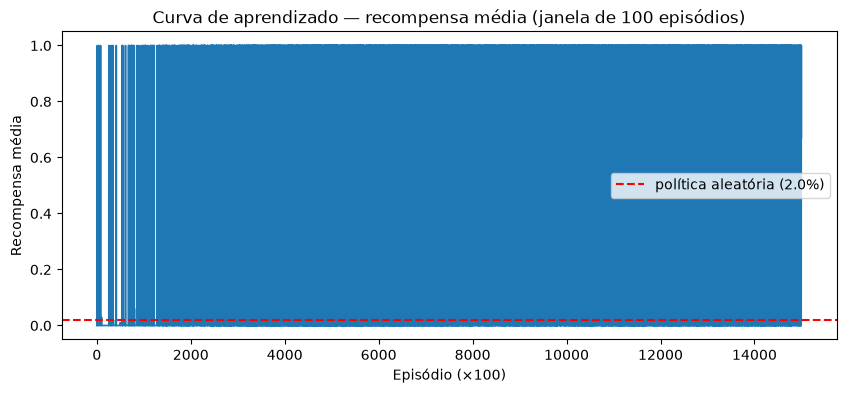

Q-Learning treinado: 70.6% de sucesso (500 episódios)


In [6]:
# ============================================================
# CURVA DE APRENDIZADO + AVALIAÇÃO DA POLÍTICA APRENDIDA
# ============================================================
fig, eixo = plt.subplots(figsize=(10, 4))
eixo.plot(historico, color="tab:blue", linewidth=1.2)
eixo.axhline(taxa_aleatoria, color="red", linestyle="--",
             label=f"política aleatória ({taxa_aleatoria:.1%})")
eixo.set_title("Curva de aprendizado — recompensa média (janela de 100 episódios)")
eixo.set_xlabel("Episódio (×100)")
eixo.set_ylabel("Recompensa média")
eixo.legend()
plt.show()

# Avaliação SEM exploração (ε = 0): política gulosa pura
def avaliar_greedy(n_episodios=500):
    vitorias = 0
    for _ in range(n_episodios):
        estado, _ = env.reset()
        term = trunc = False
        while not (term or trunc):
            estado, r, term, trunc, _ = env.step(np.argmax(Q[estado]))
        if term and r == 1.0:
            vitorias += 1
    return vitorias / n_episodios

taxa_q = avaliar_greedy()
print(f"Q-Learning treinado: {taxa_q:.1%} de sucesso (500 episódios)")

In [7]:
# ============================================================
# 📊 MARKDOWN DINÂMICO — comparativo final do Laboratório 1
# ============================================================
ganho_pp = (taxa_q - taxa_aleatoria) * 100

display(Markdown(f"""
### 📊 Relatório do Laboratório 1

| Política | Taxa de sucesso (500 episódios) |
|---|---|
| Aleatória (linha de base) | {taxa_aleatoria:.1%} |
| **Q-Learning treinado** | **{taxa_q:.1%}** |

Ganho absoluto: **{ganho_pp:.1f} pontos percentuais**.

> 💡 **Leitura do resultado:** a avaliação é gulosa (sem sorteio), logo todo o desempenho vem
> **da Q-table aprendida** — o agente descobriu sozinho uma rota que tolera o deslize aleatório
> do gelo. Note que {taxa_q:.1%} raramente chega a 100%: com `is_slippery=True`, parte do lago
> é **estatisticamente intransponível** — e conviver com incerteza também faz parte do aprendizado.
"""))


### 📊 Relatório do Laboratório 1

| Política | Taxa de sucesso (500 episódios) |
|---|---|
| Aleatória (linha de base) | 2.0% |
| **Q-Learning treinado** | **70.6%** |

Ganho absoluto: **68.6 pontos percentuais**.

> 💡 **Leitura do resultado:** a avaliação é gulosa (sem sorteio), logo todo o desempenho vem
> **da Q-table aprendida** — o agente descobriu sozinho uma rota que tolera o deslize aleatório
> do gelo. Note que 70.6% raramente chega a 100%: com `is_slippery=True`, parte do lago
> é **estatisticamente intransponível** — e conviver com incerteza também faz parte do aprendizado.


In [8]:
# ============================================================
# A POLÍTICA APRENDIDA, CÉLULA A CÉLULA
# ============================================================
setas = ["←", "↓", "→", "↑"]                    # índices 0, 1, 2, 3 do action_space
mapa = ["S","F","F","F",
        "F","H","F","H",
        "F","F","F","H",
        "F","F","F","G"]

for linha in range(4):
    celulas = []
    for col in range(4):
        s = linha * 4 + col
        if mapa[s] in ("H", "G"):
            celulas.append(f" {mapa[s]} ")       # estados finais não têm decisão
        else:
            celulas.append(f"{mapa[s]}:{setas[np.argmax(Q[s])]}")
    print(" | ".join(celulas))

# Cada célula mostra a MELHOR ação segundo a Q-table (argmax).
# Compare com o mapa impresso: a rota aprendida contorna os buracos H
# e tolera o deslize do gelo — por isso às vezes "dá voltas".

S:← | F:↑ | F:↑ | F:↑
F:← |  H  | F:← |  H 
F:↑ | F:↓ | F:← |  H 
F:← | F:→ | F:↓ |  G 


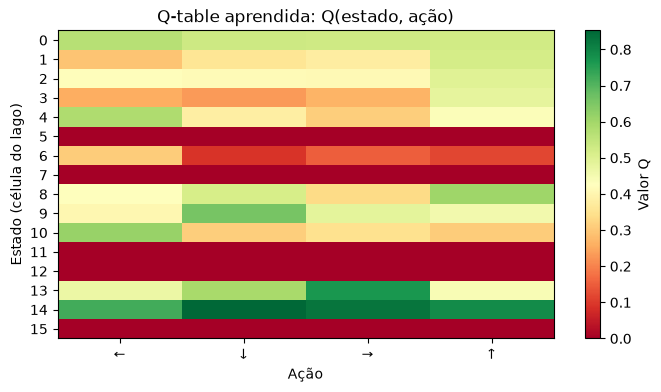

In [9]:
# ============================================================
# HEATMAP DA Q-TABLE: onde o agente "enxerga" valor
# ============================================================
fig, eixo = plt.subplots(figsize=(8, 4))
im = eixo.imshow(Q, cmap="RdYlGn", aspect="auto")
eixo.set_xticks(range(n_acoes), setas)
eixo.set_yticks(range(n_estados))
eixo.set_title("Q-table aprendida: Q(estado, ação)")
eixo.set_xlabel("Ação")
eixo.set_ylabel("Estado (célula do lago)")
fig.colorbar(im, label="Valor Q")
plt.show()
# Verde = ação com alto valor naquele estado. As linhas dos buracos (H)
# tendem a ficar quase zeradas: o agente quase nunca passa por lá.

In [10]:
# ============================================================
# 📊 MARKDOWN DINÂMICO — análise do heatmap da Q-table
# ============================================================
# Reaproveita Q, n_estados, n_acoes, setas, mapa e taxa_q das células anteriores.
# Se você retreinar o agente (outros hiperparâmetros) e reexecutar,
# esta análise se atualiza sozinha — relatório vivo.

# --- 1) Cobertura do aprendizado ---
estados_finais = [s for s in range(n_estados) if mapa[s] in ("H", "G")]
estados_aprendidos = [s for s in range(n_estados) if not np.all(Q[s] == 0)]
estados_zero_nao_finais = [
    s for s in range(n_estados)
    if np.all(Q[s] == 0) and s not in estados_finais
]

# --- 2) Top-5 pares (estado, ação) por valor Q ---
flat = Q.flatten()
top_pares = []
for i in np.argsort(flat)[::-1]:
    s, a, v = int(i // n_acoes), int(i % n_acoes), flat[i]
    if v <= 0:
        break
    top_pares.append(f"`s{s}:{setas[a]}` = {v:.3f}")
    if len(top_pares) == 5:
        break

# --- 3) Direção preferida da política aprendida ---
politica = {
    setas[a]: sum(1 for s in estados_aprendidos if np.argmax(Q[s]) == a)
    for a in range(n_acoes)
}
direcao_dominante = max(politica, key=politica.get) if estados_aprendidos else "—"
texto_politica = " · ".join(f"{d}: {n} estados" for d, n in politica.items())

# --- 4) Gradiente de valor: média do melhor Q por linha da grade ---
melhor_por_estado = Q.max(axis=1)
medias_por_linha = []
for linha in range(4):
    valores = [
        melhor_por_estado[linha * 4 + col]
        for col in range(4)
        if mapa[linha * 4 + col] in ("S", "F")
    ]
    medias_por_linha.append(float(np.mean(valores)) if valores else 0.0)
gradiente_ok = medias_por_linha[-1] > medias_por_linha[0]

# --- 5) Sínteses finais ---
q_media = (
    float(np.mean([melhor_por_estado[s] for s in estados_aprendidos]))
    if estados_aprendidos else 0.0
)
q_inicio = float(Q[0].max())
lista_finais = ", ".join(f"s{s}" for s in estados_finais)

msg_zero = (
    f"Além delas, **{len(estados_zero_nao_finais)} estado(s) não terminal(is) ficaram em zero** — "
    "o agente nunca construiu valor passando por ali."
    if estados_zero_nao_finais
    else "E **todos os estados não terminais** receberam algum aprendizado — cobertura completa do mapa navegável."
)
msg_gradiente = (
    '✅ O "calor" se concentra perto do objetivo — exatamente o que as iterações de '
    "Bellman preveem: o valor **escorre para trás** a partir da recompensa em G."
    if gradiente_ok
    else "⚠️ O gradiente esperado não se formou — vale retreinar com mais episódios ou revisar os hiperparâmetros."
)

display(Markdown(f"""
### 📊 Análise do heatmap — o que os valores Q revelam

**Cobertura do aprendizado:** {len(estados_aprendidos)} de {n_estados} estados
({len(estados_aprendidos) / n_estados:.0%}) têm pelo menos uma ação com valor aprendido.
As linhas totalmente escuras são os **estados terminais** ({lista_finais}): o episódio
termina nelas, nenhuma decisão existe ali e suas linhas permanecem em zero para sempre.
{msg_zero}

**Os pontos mais valiosos do mapa:** {' · '.join(top_pares)} — valores próximos de
**1.0** marcam estados de onde alcançar o G é quase certeza.

**A rota em números:** a direção dominante da política é **{direcao_dominante}**
({texto_politica}) — a "seta geral" aponta para o canto inferior direito, onde vive o objetivo.

**O gradiente vertical:** a média do melhor valor por linha da grade vai de
**{medias_por_linha[0]:.3f}** no topo até **{medias_por_linha[-1]:.3f}** na base. {msg_gradiente}

> 💡 **A leitura-chave deste mapa:** como a ÚNICA recompensa do FrozenLake é 1 no objetivo,
> cada valor Q funciona como uma **probabilidade descontada de vitória**. Um valor 0.85 significa
> "daqui, seguindo a melhor política, ~85% de chance de chegar ao G (descontado por γ = 0.99)".
> Confira a coerência: no estado inicial (s0) o agente já espera vencer **{q_inicio:.0%}**
> das vezes, a média dos melhores valores é **{q_media:.2f}**, e a taxa de sucesso greedy
> medida antes foi **{taxa_q:.1%}** — três métricas independentes contando a mesma história.
> O heatmap não é enfeite: é a **previsão quantitativa** do comportamento do agente.
"""))


### 📊 Análise do heatmap — o que os valores Q revelam

**Cobertura do aprendizado:** 11 de 16 estados
(69%) têm pelo menos uma ação com valor aprendido.
As linhas totalmente escuras são os **estados terminais** (s5, s7, s11, s15): o episódio
termina nelas, nenhuma decisão existe ali e suas linhas permanecem em zero para sempre.
Além delas, **1 estado(s) não terminal(is) ficaram em zero** — o agente nunca construiu valor passando por ali.

**Os pontos mais valiosos do mapa:** `s14:↓` = 0.853 · `s14:→` = 0.828 · `s14:↑` = 0.787 · `s13:→` = 0.768 · `s14:←` = 0.721 — valores próximos de
**1.0** marcam estados de onde alcançar o G é quase certeza.

**A rota em números:** a direção dominante da política é **←**
(←: 4 estados · ↓: 2 estados · →: 1 estados · ↑: 4 estados) — a "seta geral" aponta para o canto inferior direito, onde vive o objetivo.

**O gradiente vertical:** a média do melhor valor por linha da grade vai de
**0.515** no topo até **0.540** na base. ✅ O "calor" se concentra perto do objetivo — exatamente o que as iterações de Bellman preveem: o valor **escorre para trás** a partir da recompensa em G.

> 💡 **A leitura-chave deste mapa:** como a ÚNICA recompensa do FrozenLake é 1 no objetivo,
> cada valor Q funciona como uma **probabilidade descontada de vitória**. Um valor 0.85 significa
> "daqui, seguindo a melhor política, ~85% de chance de chegar ao G (descontado por γ = 0.99)".
> Confira a coerência: no estado inicial (s0) o agente já espera vencer **57%**
> das vezes, a média dos melhores valores é **0.59**, e a taxa de sucesso greedy
> medida antes foi **70.6%** — três métricas independentes contando a mesma história.
> O heatmap não é enfeite: é a **previsão quantitativa** do comportamento do agente.


## 3. Laboratório 2 — Agente de trading com dados REAIS de mercado

Agora levamos a **mesma máquina de Q-Learning** para um problema real: decidir, dia a dia,
se vale a pena estar **investido** ou **fora do mercado** numa ação da B3 — usando preços
reais baixados da internet (Yahoo Finance, via `yfinance`).

**Como traduzimos o problema para RL:**

| Componente RL | Nossa escolha | Por quê |
|---|---|---|
| **Ação** | `0` = fora do mercado · `1` = investido | Decisão binária, didática |
| **Estado** | (momento, tendência, posição atual) | Números discretos cabem numa Q-table |
| **Recompensa** | retorno diário da ação − custo de transação | Se investido e a ação sobe, ganha; se cai, perde |
| **Episódio** | uma passada completa pelo histórico de treino | O agente revive a série muitas vezes |

**O Estado em detalhe** (discretização — obrigatória para Q-Learning tabular):
- **Momento**: retorno dos últimos 5 dias, cortado em 3 níveis (baixo/médio/alto pelos *quantis do treino*);
- **Tendência**: preço acima ou abaixo da média móvel de 20 dias (2 níveis);
- **Posição atual**: investido ou não (2 níveis) → **12 estados × 2 ações**.

> ⚠️ **Disciplina científica:** os cortes de quantis são calculados **só com dados de treino**
> e depois aplicados ao teste — nunca o contrário. Avaliaremos o agente em um período
> que ele **nunca viu** (leak de futuro é o erro mais comum em backtests).

Série completa: 2945 pregões | treino: 2487 | teste: 458


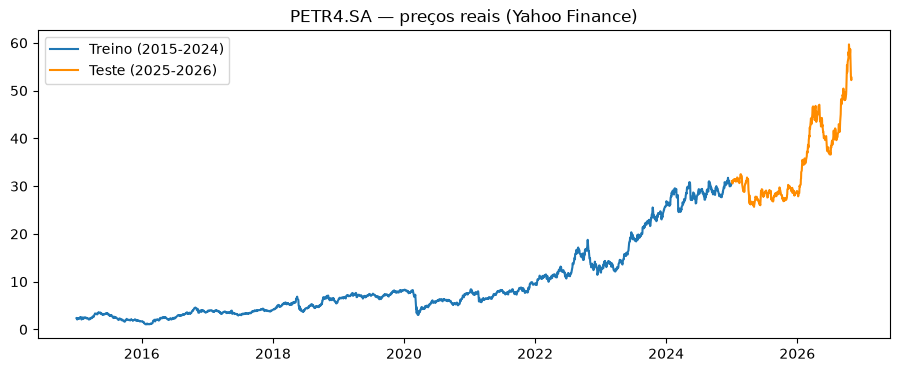

In [11]:
# ============================================================
# DADOS REAIS DA INTERNET: PETR4 (Petrobras) via Yahoo Finance
# ============================================================
import yfinance as yf

TICKER = "PETR4.SA"
acao = yf.Ticker(TICKER)
df = acao.history(start="2015-01-01", end="2026-11-01", auto_adjust=True)[["Close"]].dropna()
df["retorno"] = df["Close"].pct_change()

# ---- Divisão temporal: treino (2015-2024) e teste (2025-2026) ----
treino = df.loc[:"2024-12-31"].copy()
teste  = df.loc["2025-01-01":].copy()

print(f"Série completa: {len(df)} pregões | treino: {len(treino)} | teste: {len(teste)}")

# Visualização rápida
fig, eixo = plt.subplots(figsize=(11, 4))
eixo.plot(treino["Close"], label="Treino (2015-2024)")
eixo.plot(teste["Close"], label="Teste (2025-2026)", color="darkorange")
eixo.set_title(f"{TICKER} — preços reais (Yahoo Finance)")
eixo.legend()
plt.show()

In [12]:
# ============================================================
# FEATURE ENGINEERING + DISCRETIZAÇÃO (sem leak de futuro!)
# ============================================================
for base in (treino, teste):
    base["mm20"]     = base["Close"].rolling(20).mean()
    base["momento"]  = base["Close"].pct_change(5)
    base.dropna(inplace=True)

# Cortes de quantil calculados SOMENTE com dados de treino
cortes = treino["momento"].quantile([1/3, 2/3]).values
print(f"Cortes do momento (treino): {cortes.round(4)}")

def nivel_momento(x):
    """Converte o retorno de 5 dias em 3 níveis discretos."""
    if x <= cortes[0]: return 0        # momento baixo
    if x <= cortes[1]: return 1        # momento médio
    return 2                           # momento alto

for base in (treino, teste):
    base["nivel_momento"]   = base["momento"].apply(nivel_momento)
    base["nivel_tendencia"] = (base["Close"] > base["mm20"]).astype(int)  # 0=abaixo, 1=acima

Cortes do momento (treino): [-0.0129  0.0283]


In [13]:
# ============================================================
# AMBIENTE CUSTOMIZADO DE TRADING (padrão Gymnasium)
# ============================================================
from gymnasium import spaces

class AmbienteTrading(gym.Env):
    """
    Ambiente de trading tabular.

    Estado  = nivel_momento(0-2) * 4 + nivel_tendencia(0-1) * 2 + posicao(0-1)  →  12 estados
    Ação    = 0 (sair do mercado) | 1 (ficar investido)
    Recompensa = posicao * retorno_do_dia − custo_de_transacao_se_trocou_de_posicao
    """
    def __init__(self, dados, custo_transacao=0.001):
        super().__init__()
        self.dados = dados.reset_index(drop=True)
        self.custo = custo_transacao
        self.n_estados, self.n_acoes = 12, 2
        self.action_space = spaces.Discrete(self.n_acoes)
        self.observation_space = spaces.Discrete(self.n_estados)

    def _estado(self, i):
        d = self.dados.iloc[i]
        # int() em cada componente: ao extrair a linha com .iloc[i], o pandas
        # converte TODAS as colunas para float (upcasting de tipos mistos).
        # Sem o cast, o estado sai como 6.0 e o numpy rejeita Q[6.0].
        return int(d["nivel_momento"]) * 4 + int(d["nivel_tendencia"]) * 2 + int(self.posicao)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.i = 0
        self.posicao = 0                      # todo episódio começa fora do mercado
        return self._estado(0), {}

    def step(self, acao):
        i = self.i
        nova_posicao = acao
        custo = self.custo if nova_posicao != self.posicao else 0.0
        self.posicao = nova_posicao
        # recompensa = retorno do PRÓXIMO dia aplicado à posição escolhida
        recompensa = self.posicao * self.dados.iloc[i + 1]["retorno"] - custo
        self.i += 1
        terminado = self.i >= len(self.dados) - 2   # precisa existir "próximo dia"
        return self._estado(self.i), recompensa, terminado, False, {}

env_trade = AmbienteTrading(treino)

In [14]:
# ============================================================
# TREINO: o MESMO loop de Q-Learning do FrozenLake
# ============================================================
Q_trade = np.zeros((env_trade.n_estados, env_trade.n_acoes))

alpha, gamma   = 0.1, 0.95          # desconto menor: séries financeiras mudam de regime
epsilon, eps_min, eps_decay = 1.0, 0.05, 0.995
n_episodios, janela = 400, 20

historico_trade = []
for episodio in range(n_episodios):
    estado, _ = env_trade.reset()
    term = False
    retorno_episodio = 0.0
    while not term:
        acao = env_trade.action_space.sample() if np.random.random() < epsilon else np.argmax(Q_trade[estado])
        proximo, r, term, _, _ = env_trade.step(acao)
        alvo = r + gamma * np.max(Q_trade[proximo])
        Q_trade[estado, acao] += alpha * (alvo - Q_trade[estado, acao])
        estado = proximo
        retorno_episodio += r
    epsilon = max(eps_min, epsilon * eps_decay)
    historico_trade.append(retorno_episodio)
    if (episodio + 1) % janela == 0:
        historico_trade[-1] = float(np.mean(historico_trade[-janela:]))

print("Treino concluído.")

Treino concluído.


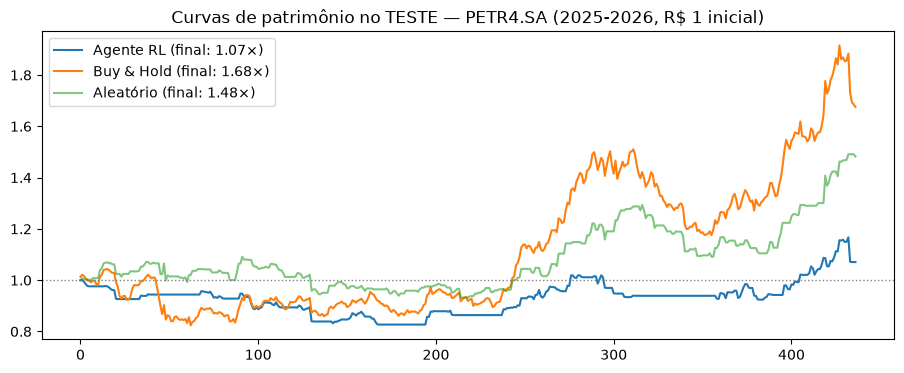

In [15]:
# ============================================================
# AVALIAÇÃO NO PERÍODO DE TESTE (dados nunca vistos)
# ============================================================
env_teste = AmbienteTrading(teste)
estado, _ = env_teste.reset()
term = False
retornos_agente = []
while not term:
    estado, r, term, _, _ = env_teste.step(np.argmax(Q_trade[estado]))   # política greedy
    retornos_agente.append(r)

retornos_bh = teste["retorno"].iloc[1:len(retornos_agente)+1].values   # buy & hold
rng = np.random.default_rng(SEED)
retornos_aleat = [rng.integers(0, 2) * r for r in retornos_bh]          # trader aleatório

patrimonio = lambda r: float(np.prod(1 + np.array(r)))                  # R$ 1 inicial
curva = lambda r: np.cumprod(1 + np.array(r))

fig, eixo = plt.subplots(figsize=(11, 4))
eixo.plot(curva(retornos_agente), label=f"Agente RL (final: {patrimonio(retornos_agente):.2f}×)")
eixo.plot(curva(retornos_bh),     label=f"Buy & Hold (final: {patrimonio(retornos_bh):.2f}×)")
eixo.plot(curva(retornos_aleat),  label=f"Aleatório (final: {patrimonio(retornos_aleat):.2f}×)", alpha=0.6)
eixo.axhline(1.0, color="gray", linestyle=":", linewidth=1)
eixo.set_title(f"Curvas de patrimônio no TESTE — {TICKER} (2025-2026, R$ 1 inicial)")
eixo.legend()
plt.show()

In [16]:
# ============================================================
# 📊 MARKDOWN DINÂMICO — relatório final do Laboratório 2
# ============================================================
p_ag, p_bh, p_al = patrimonio(retornos_agente), patrimonio(retornos_bh), patrimonio(retornos_aleat)
venceu = p_ag > p_bh

display(Markdown(f"""
### 📊 Relatório do Laboratório 2 — {TICKER} no teste (2025-2026)

| Estratégia | Patrimônio final (R$ 1 investido) | Retorno total |
|---|---|---|
| **Agente Q-Learning** | **{p_ag:.2f}×** | **{(p_ag-1):+.1%}** |
| Buy & Hold | {p_bh:.2f}× | {(p_bh-1):+.1%} |
| Trader aleatório | {p_al:.2f}× | {(p_al-1):+.1%} |

> 💡 **Leitura do resultado:** o agente {'**venceu** o Buy & Hold' if venceu else 'não venceu o Buy & Hold'} no período de teste.
> O mais importante **não é vencer em um único período** — é que a decisão saiu de uma
> Q-table aprendida **sem ver esse período nunca**, com apenas 12 estados. Note também
> o custo do trader aleatório: trocar de posição sem critério paga custo de transação
> repetidamente, e isso corrói o patrimônio. Em finanças, **evitar perdas evitáveis já é alpha**.
"""))


### 📊 Relatório do Laboratório 2 — PETR4.SA no teste (2025-2026)

| Estratégia | Patrimônio final (R$ 1 investido) | Retorno total |
|---|---|---|
| **Agente Q-Learning** | **1.07×** | **+7.1%** |
| Buy & Hold | 1.68× | +67.5% |
| Trader aleatório | 1.48× | +48.2% |

> 💡 **Leitura do resultado:** o agente não venceu o Buy & Hold no período de teste.
> O mais importante **não é vencer em um único período** — é que a decisão saiu de uma
> Q-table aprendida **sem ver esse período nunca**, com apenas 12 estados. Note também
> o custo do trader aleatório: trocar de posição sem critério paga custo de transação
> repetidamente, e isso corrói o patrimônio. Em finanças, **evitar perdas evitáveis já é alpha**.


### 3.1 O que este laboratório nos ensinou (e o que ele NÃO promete)

O agente com 12 estados aprendeu um padrão simples de **momento + tendência** e o aplicou
a um futuro que nunca viu. Isso é a essência do RL: transformar **experiência em política**.

**Limitações honestas do que construimos:**

1. **Estado empobrecedo** — 12 estados ignoram volume, volatilidade, contexto macro. Informação real de mercado é **contínua e multidimensional**;
2. **Q-table não escala** — com 50 features discretizadas em 10 níveis teríamos $10^{50}$ estados: impossível. A solução moderna é **aproximar** Q(s,a) com redes neurais (**DQN**, Deep Q-Network);
3. **Mercados são não-estacionários** — o padrão de 2015 pode morrer em 2026; nenhum backtest garante o futuro;
4. **Custo de transação e slippage** — simplificamos com 0.1%; na prática dependem de liquidez.

> ⚠️ **Aviso de responsabilidade:** este notebook é **didático**. Nada aqui é recomendação de investimento — operar com modelos exige infraestrutura, validação estatística séria e gestão de risco profissional.

## 3-B. Laboratório 2-B — A mesma tarefa, agora com Redes Neurais (DQN)

### O problema que a Q-table não resolve

No Laboratório 2, o estado foi **discretizado à força** em 12 combinações: perdemos informação
ao cortar o retorno de 5 dias em só 3 níveis e ignorar volatilidade, volume e contexto. Pior:
a estratégia não escala — com 50 features discretizadas em 10 níveis teríamos $10^{50}$ estados.
A solução moderna é **aproximar** a função Q em vez de tabelá-la.

### A ideia do DQN

Substituímos a Q-table por uma **rede neural** $Q_\theta(s,a)$ com parâmetros $\theta$:

$$Q(s,a) \approx Q_\theta(s,a)$$

- **Entrada:** o estado **contínuo** (vetor de features, sem discretização);
- **Saída:** um valor Q **por ação** numa única passada (rede com `n_acoes` neurônios de saída);
- **Treino por regressão:** minimizamos o erro entre a previsão e o alvo de Bellman:

$$\mathcal{L}(\theta) = \Big( \underbrace{r + \gamma \max_{a'} Q_{\theta^-}(s',a')}_{\text{alvo}} - Q_\theta(s,a) \Big)^2$$

### Por que "rede + Bellman" ingênuo DIVERGE

Treinar uma rede contra um alvo que **ela própria produz** é instável por dois motivos:
1. **Amostras correlacionadas:** os passos consecutivos de um episódio são quase iguais —
   a rede aprende em "sequências", não em experiências independentes;
2. **Alvo móvel:** a cada atualização de $\theta$, o alvo muda junto — o agente persegue um chão que se move.

O DQN (DeepMind, *Nature* 2015) resolve com **dois truques**:

| Truque | O que faz | Por que estabiliza |
|---|---|---|
| **Experience Replay** | Guarda transições $(s,a,r,s')$ num buffer e treina com **minilotes aleatórios** | Quebra a correlação temporal e reaproveita experiências |
| **Rede-alvo** ($Q_{\theta^-}$) | Uma **cópia congelada** da rede, sincronizada só de vez em quando | O alvo fica fixo durante o aprendizado |

**O ciclo de treino:** interagir → guardar no buffer → amostrar minilote → atualizar rede online → sincronizar rede-alvo periodicamente.

In [17]:
# ============================================================
# PYTORCH: a biblioteca de redes neurais (executar 1x)
# ============================================================
# !pip install torch --quiet   # descomente se ainda não tiver o PyTorch

import torch
import torch.nn as nn
from collections import deque

# Reprodutibilidade também no PyTorch
torch.manual_seed(SEED)

# CPU dá conta desta rede pequena; se houver GPU, usamos
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | device: {device}")

PyTorch 2.5.1+cu121 | device: cuda


### 3-B.1 O novo estado: contínuo e mais rico

Sem a limitação da Q-table, o estado deixa de ser 12 combinações e vira um **vetor contínuo de 5 dimensões**:

| # | Feature | O que captura |
|---|---|---|
| 1 | `momento5` | Retorno dos últimos 5 dias (pressão de curto prazo) |
| 2 | `momento20` | Retorno dos últimos 20 dias (tendência do mês) |
| 3 | `vol20` | Volatilidade de 20 dias (desvio-padrão dos retornos) |
| 4 | `dist_mm` | Distância do preço até a média móvel de 20 dias |
| 5 | `posicao` | Se o agente está investido (0/1) — o agente precisa "saber" onde está |

**Normalização z-score com disciplina anti-vazamento:** cada feature vira
$\frac{x - \mu}{\sigma}$, com $\mu$ e $\sigma$ calculados **somente no treino** e reaplicados
no teste — o modelo não pode "espiar" estatísticas do futuro.

> 💡 Compare com o laboratório tabular: lá, 4 features viravam 12 estados. Aqui, o mesmo
> espaço (e mais) vira um vetor contínuo — a rede generaliza entre estados vizinhos, coisa
> que a Q-table não consegue: o que ela aprende num estado **não vaza** para o vizinho.

In [18]:
# ============================================================
# FEATURES CONTÍNUAS + NORMALIZAÇÃO SEM VAZAMENTO
# ============================================================
# Depende apenas das células de dados (19): df, treino, teste, TICKER

for base in (treino, teste):
    base["mm20"]      = base["Close"].rolling(20).mean()
    base["momento5"]  = base["Close"].pct_change(5)
    base["momento20"] = base["Close"].pct_change(20)
    base["vol20"]     = base["retorno"].rolling(20).std()
    base["dist_mm"]   = base["Close"] / base["mm20"] - 1

FEATURES = ["momento5", "momento20", "vol20", "dist_mm"]

# Remove as linhas de "aquecimento" dos indicadores (20 primeiras)
matriz_treino = treino[FEATURES].dropna()
matriz_teste  = teste[FEATURES].dropna()

# ---- Normalização: média/desvio calculados SÓ com treino ----
media  = matriz_treino.mean()
desvio = matriz_treino.std() + 1e-8          # epsilon evita divisão por zero

X_treino = ((matriz_treino - media) / desvio).to_numpy(dtype=np.float32)
X_teste  = ((matriz_teste  - media) / desvio).to_numpy(dtype=np.float32)

# Dataframes alinhados às linhas válidas (para a coluna "retorno")
treino_dqn = treino.loc[matriz_treino.index].copy()
teste_dqn  = teste.loc[matriz_teste.index].copy()

print(f"Treino: {X_treino.shape[0]} dias × {X_treino.shape[1]} features")
print(f"Teste:  {X_teste.shape[0]} dias × {X_teste.shape[1]} features")

Treino: 2448 dias × 4 features
Teste:  419 dias × 4 features


In [19]:
# ============================================================
# AMBIENTE DE TRADING COM ESTADO CONTÍNUO (padrão Gymnasium)
# ============================================================
class AmbienteTradingDQN(gym.Env):
    """
    Ambiente de trading para DQN.

    obs        = vetor contínuo: [4 features normalizadas, posição atual] → 5 dimensões
    ação       = 0 (fora do mercado) | 1 (investido)
    recompensa = posição × retorno do próximo dia − custo_de_transacao_se_trocou
    Observação: a posição atual entra NO ESTADO — o agente precisa saber
    se está investido para pesar o custo de trocar de posição.
    """
    def __init__(self, X, retornos, custo_transacao=0.001):
        super().__init__()
        self.X = X
        self.retornos = np.asarray(retornos, dtype=np.float32)
        self.custo = custo_transacao
        self.n_acoes = 2
        self.dim_estado = X.shape[1] + 1              # features + posição
        self.action_space = spaces.Discrete(self.n_acoes)
        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf,
            shape=(self.dim_estado,), dtype=np.float32,
        )

    def _obs(self):
        return np.append(self.X[self.i], self.posicao).astype(np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.i = 0
        self.posicao = 0                              # episódio começa fora do mercado
        return self._obs(), {}

    def step(self, acao):
        custo = self.custo if acao != self.posicao else 0.0
        self.posicao = acao
        # recompensa = retorno do PRÓXIMO dia aplicado à posição escolhida
        recompensa = self.posicao * self.retornos[self.i + 1] - custo
        self.i += 1
        terminado = self.i >= len(self.retornos) - 2  # precisa existir "próximo dia"
        return self._obs(), float(recompensa), terminado, False, {}

env_dqn = AmbienteTradingDQN(X_treino, treino_dqn["retorno"].values, custo_transacao=0.001)
print(f"Ambiente criado | estado: {env_dqn.dim_estado} dimensões contínuas | ações: {env_dqn.n_acoes}")

Ambiente criado | estado: 5 dimensões contínuas | ações: 2


In [20]:
# ============================================================
# A REDE Q E O BUFFER DE EXPERIÊNCIAS
# ============================================================
class QRede(nn.Module):
    """
    MLP que recebe o estado e devolve UM VALOR Q POR AÇÃO.
    5 entradas → 64 → 64 → 2 saídas. Arquitetura pequena de propósito:
    o gargalo deste problema é o sinal (dados diários), não a capacidade.
    """
    def __init__(self, dim_estado, n_acoes, n_neuronios=64):
        super().__init__()
        self.camadas = nn.Sequential(
            nn.Linear(dim_estado, n_neuronios),
            nn.ReLU(),
            nn.Linear(n_neuronios, n_neuronios),
            nn.ReLU(),
            nn.Linear(n_neuronios, n_acoes),   # uma passada devolve Q(s, TODAS as ações)
        )

    def forward(self, x):
        return self.camadas(x)


class BufferExperiencias:
    """
    Experience Replay: memória circular de transições (s, a, r, s', terminou).
    O treino amostra minilotes ALEATÓRIOS — quebra a correlação temporal
    entre passos consecutivos e reaproveita cada experiência várias vezes.
    """
    def __init__(self, capacidade=50_000):
        self.buffer = deque(maxlen=capacidade)

    def push(self, s, a, r, s2, term):
        self.buffer.append((s, a, r, s2, term))

    def sample(self, tamanho):
        lote = random.sample(self.buffer, tamanho)
        s, a, r, s2, term = zip(*lote)
        return (
            torch.tensor(np.array(s),  device=device),
            torch.tensor(a, dtype=torch.long, device=device),
            torch.tensor(r, dtype=torch.float32, device=device),
            torch.tensor(np.array(s2), device=device),
            torch.tensor(term, dtype=torch.float32, device=device),
        )

    def __len__(self):
        return len(self.buffer)

In [21]:
# ============================================================
# O AGENTE DQN COMPLETO
# ============================================================
class AgenteDQN:
    """
    DQN com rede online, rede-alvo, replay buffer e epsilon-greedy.
    As duas redes têm a MESMA arquitetura; a rede-alvo é uma cópia
    congelada, sincronizada apenas quando chamamos sincronizar_alvo().
    """
    def __init__(self, dim_estado, n_acoes, lr=1e-3, gamma=0.95):
        self.q_online = QRede(dim_estado, n_acoes).to(device)
        self.q_alvo   = QRede(dim_estado, n_acoes).to(device)
        self.q_alvo.load_state_dict(self.q_online.state_dict())  # cópia inicial
        self.q_alvo.eval()                                       # sempre em modo inferência
        self.otimizador = torch.optim.Adam(self.q_online.parameters(), lr=lr)
        self.perda = nn.HuberLoss()      # Huber: menos explosiva que MSE com alvos de RL
        self.gamma = gamma
        self.n_acoes = n_acoes
        self.buffer = BufferExperiencias()
        self.historico_perda = []

    def escolher(self, obs, epsilon):
        """ε-greedy: sorteia com probabilidade ε; senão, melhor ação da rede."""
        if np.random.random() < epsilon:
            return np.random.randint(self.n_acoes)               # EXPLORA
        with torch.no_grad():
            q = self.q_online(torch.tensor(obs, device=device).unsqueeze(0))
            return int(q.argmax().item())                        # EXPLOTA

    def aprender(self, tamanho_lote=64):
        """Um passo de gradiente: aproxima Q_θ(s,a) do alvo de Bellman."""
        if len(self.buffer) < tamanho_lote:
            return                                                # buffer ainda pequeno
        s, a, r, s2, term = self.buffer.sample(tamanho_lote)

        # Q(s,a) PREVISTO: só da ação efetivamente tomada (gather seleciona a coluna)
        q_previsto = self.q_online(s).gather(1, a.unsqueeze(1)).squeeze(1)

        # ALVO: r + γ · max Q_alvo(s') — zerado se o episódio terminou
        with torch.no_grad():                                     # o alvo NÃO recebe gradiente
            q_futuro = self.q_alvo(s2).max(dim=1).values
            alvo = r + self.gamma * q_futuro * (1 - term)

        perda = self.perda(q_previsto, alvo)
        self.otimizador.zero_grad()
        perda.backward()
        torch.nn.utils.clip_grad_norm_(self.q_online.parameters(), 10.0)  # trava explosões
        self.otimizador.step()
        self.historico_perda.append(perda.item())

    def sincronizar_alvo(self):
        """Copia os pesos da rede online para a rede-alvo."""
        self.q_alvo.load_state_dict(self.q_online.state_dict())

agente = AgenteDQN(dim_estado=env_dqn.dim_estado, n_acoes=env_dqn.n_acoes)
n_parametros = sum(p.numel() for p in agente.q_online.parameters())
print(f"Rede Q criada: {n_parametros} parâmetros — contra 24 números da Q-table do Lab 2 (12×2)")

Rede Q criada: 4674 parâmetros — contra 24 números da Q-table do Lab 2 (12×2)


In [22]:
# ============================================================
# TREINO DO DQN
# ============================================================
# O loop é o MESMO esqueleto do Q-Learning tabular (Célula 13):
# interagir → guardar → aprender. O que mudou está DENTRO de aprender().
# ⏱️ Em CPU leva ~3-6 min. Para a aula, dá para reduzir n_episodios_dqn
# para 80 e ainda ver a curva de aprendizado se formar.

epsilon, eps_min, eps_decay = 1.0, 0.05, 0.98
n_episodios_dqn = 150

historico_retorno, historico_eps = [], []

for episodio in range(n_episodios_dqn):
    obs, _ = env_dqn.reset()
    term = False
    retorno_episodio = 0.0
    while not term:
        acao = agente.escolher(obs, epsilon)
        proximo, r, term, _, _ = env_dqn.step(acao)
        agente.buffer.push(obs, acao, r, proximo, term)   # guarda a transição
        agente.aprender()                                 # um passo de gradiente
        obs = proximo
        retorno_episodio += r
    agente.sincronizar_alvo()                             # rede-alvo congela de novo
    epsilon = max(eps_min, epsilon * eps_decay)
    historico_retorno.append(retorno_episodio)
    historico_eps.append(epsilon)
    if (episodio + 1) % 25 == 0:
        print(f"episódio {episodio+1:3d} | retorno acumulado: {retorno_episodio:+.4f} | ε: {epsilon:.2f}")

print("Treino concluído.")

episódio  25 | retorno acumulado: +2.8571 | ε: 0.60
episódio  50 | retorno acumulado: +6.9254 | ε: 0.36
episódio  75 | retorno acumulado: +7.3698 | ε: 0.22
episódio 100 | retorno acumulado: +7.9091 | ε: 0.13
episódio 125 | retorno acumulado: +9.7399 | ε: 0.08
episódio 150 | retorno acumulado: +11.0993 | ε: 0.05
Treino concluído.


### 📖 Os hiperparâmetros do nosso DQN

Hiperparâmetro é toda **escolha feita antes do treino** que o próprio treino não ajusta:
a rede aprende os pesos; os hiperparâmetros decidem **como, por quanto tempo e com quanta
curiosidade** ela aprende. Não existe valor universal — existe o experimento.

| Hiperparâmetro | Papel na teoria | Muito baixo | Muito alto | Nosso padrão |
|---|---|---|---|---|
| **Episódios** (`n_episodios_dqn`) | Tempo de experiência | Não aprende | Sobreajuste ao passado | 150 |
| **Neurônios** (`n_neuronios`) | Capacidade da rede | Só padrões simples | Decora ruído | 64 |
| **Taxa de aprendizado** (`lr`) | Passo de correção dos pesos ($\alpha$ da teoria) | Lento demais | Oscila/diverge | 1e-3 |
| **Desconto** ($\gamma$) | Peso do futuro no alvo de Bellman | Míope (day trader) | Ignora o presente | 0.95 |
| **Decaimento do ε** (`eps_decay`) | Cronograma exploração→explotação | Trava cedo | Explora demais | 0.98 |
| **Piso do ε** (`eps_min`) | Exploração residual | Fica "convencido" | — | 0.05 |
| **Minilote** (`tamanho_lote`) | Estabilidade do gradiente | Ruidoso | Lento | 64 |

**Os dois mais conceituais, em detalhe:**

**Taxa de aprendizado** — o tamanho do passo que o otimizador (Adam) dá ao corrigir
os pesos a cada erro, o mesmo papel do $\alpha$ na atualização do Q-Learning tabular:

$$\theta \leftarrow \theta - lr \cdot \nabla_\theta \mathcal{L}(\theta)$$

Com $lr = 10^{-2}$ os pesos oscilam violentamente; com $10^{-5}$ o aprendizado é glacial —
150 episódios não bastam. O $10^{-3}$ é o ponto de partida consagrado para MLPs pequenas.

**Fator de desconto $\gamma$** — quanto o agente valoriza o futuro ao montar o alvo:

$$\text{alvo} = r + \gamma \cdot \max_{a'} Q_{\theta^-}(s', a')$$

Com $\gamma = 0.80$, o retorno de 5 dias adiante pesa $0.80^5 \approx 33\%$ — o agente
vira "day trader" míope. Com $0.99$, o que acontece em 20 dias ainda pesa $\sim 82\%$ —
o agente aceita perdas hoje por ganhos maiores depois. O $0.95$ equilibra o horizonte
para dados **diários** (o ganho de ~14 dias adiante ainda pesa metade).

> 💡 **Exercício mental:** a Q-table do Lab 2 tinha **24 números** (12 estados × 2 ações).
> A rede de 64 neurônios tem **~4.800 parâmetros**. Mais capacidade não é melhor por si só:
> com ~2.400 dias de treino, o gargalo é o **sinal**, não a rede. Experimente `n_neuronios = 16`
> e `= 256` no treino e compare as curvas de perda — é o exercício 5 do fim do notebook.

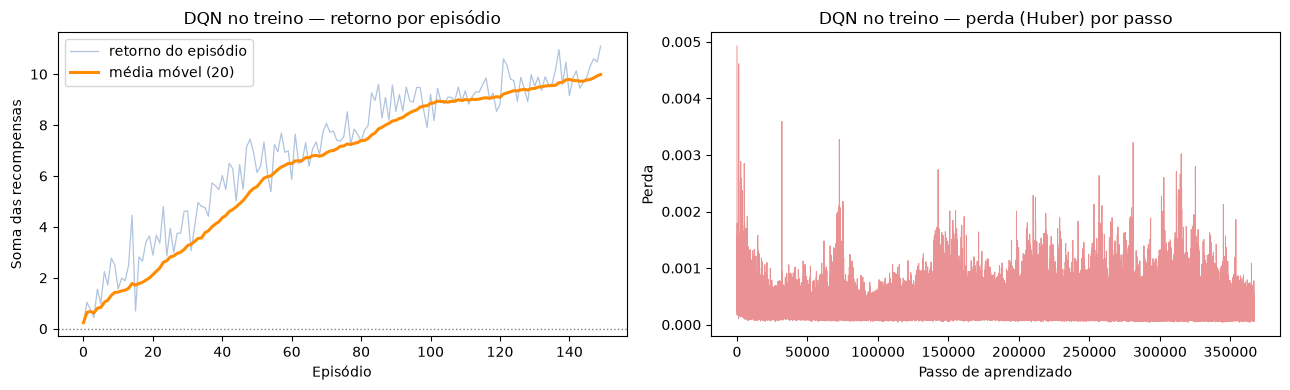

In [23]:
# ============================================================
# CURVAS DE APRENDIZADO DO DQN (treino)
# ============================================================
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

# Painel 1: retorno acumulado por episódio + média móvel
eixos[0].plot(historico_retorno, color="lightsteelblue", linewidth=0.9, label="retorno do episódio")
janela_mm = 20
medias = [float(np.mean(historico_retorno[max(0, i - janela_mm + 1): i + 1]))
          for i in range(len(historico_retorno))]
eixos[0].plot(medias, color="darkorange", linewidth=2.2, label=f"média móvel ({janela_mm})")
eixos[0].axhline(0, color="gray", linestyle=":", linewidth=1)
eixos[0].set_title("DQN no treino — retorno por episódio")
eixos[0].set_xlabel("Episódio")
eixos[0].set_ylabel("Soma das recompensas")
eixos[0].legend()

# Painel 2: perda por passo de gradiente
# A perda caindo = as previsões Q(s,a) convergindo para os alvos de Bellman
eixos[1].plot(agente.historico_perda, color="tab:red", linewidth=0.7, alpha=0.5)
eixos[1].set_title("DQN no treino — perda (Huber) por passo")
eixos[1].set_xlabel("Passo de aprendizado")
eixos[1].set_ylabel("Perda")

plt.tight_layout()
plt.show()

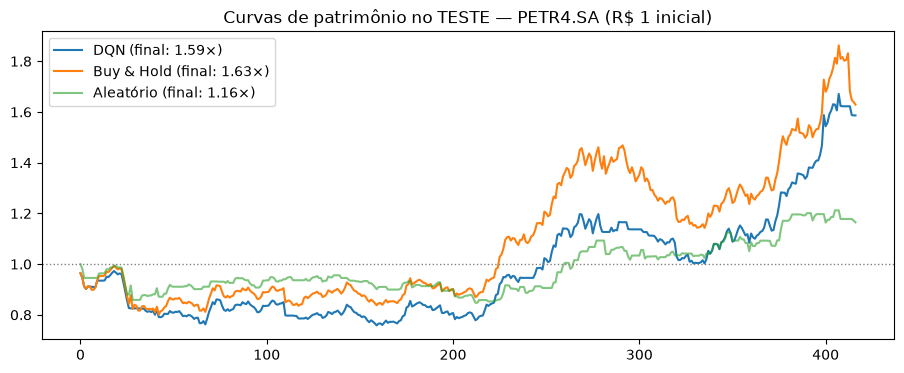

In [24]:
# ============================================================
# AVALIAÇÃO DO DQN NO PERÍODO DE TESTE (dados nunca vistos)
# ============================================================
# Autossuficiente: define as funções de patrimônio para funcionar
# mesmo que as células do Lab 2 tabular tenham sido removidas.

env_teste_dqn = AmbienteTradingDQN(X_teste, teste_dqn["retorno"].values, custo_transacao=0.001)

obs, _ = env_teste_dqn.reset()
term = False
retornos_dqn = []
while not term:
    obs, r, term, _, _ = env_teste_dqn.step(agente.escolher(obs, epsilon=0.0))  # política greedy
    retornos_dqn.append(r)

n = len(retornos_dqn)
retornos_bh_dqn  = teste_dqn["retorno"].iloc[1:n+1].values            # buy & hold
rng_dqn = np.random.default_rng(SEED)
retornos_aleat_dqn = [rng_dqn.integers(0, 2) * r for r in retornos_bh_dqn]  # trader aleatório

patrimonio = lambda r: float(np.prod(1 + np.array(r)))                # R$ 1 inicial
curva = lambda r: np.cumprod(1 + np.array(r))

fig, eixo = plt.subplots(figsize=(11, 4))
eixo.plot(curva(retornos_dqn),      label=f"DQN (final: {patrimonio(retornos_dqn):.2f}×)")
eixo.plot(curva(retornos_bh_dqn),   label=f"Buy & Hold (final: {patrimonio(retornos_bh_dqn):.2f}×)")
eixo.plot(curva(retornos_aleat_dqn),label=f"Aleatório (final: {patrimonio(retornos_aleat_dqn):.2f}×)", alpha=0.6)
eixo.axhline(1.0, color="gray", linestyle=":", linewidth=1)
eixo.set_title(f"Curvas de patrimônio no TESTE — {TICKER} (R$ 1 inicial)")
eixo.legend()
plt.show()

In [25]:
# ============================================================
# 📊 MARKDOWN DINÂMICO — relatório final: Q-table vs DQN
# ============================================================
p_dqn = patrimonio(retornos_dqn)
p_bh  = patrimonio(retornos_bh_dqn)
p_al  = patrimonio(retornos_aleat_dqn)
venceu_dqn = p_dqn > p_bh

# Detecta se o Lab 2 tabular também foi executado (para comparar lado a lado)
if "retornos_agente" in globals():
    p_tab = patrimonio(retornos_agente)
    linha_tabular = f"| Q-Learning tabular (Lab 2, 12 estados) | {p_tab:.2f}× | {(p_tab-1):+.1%} |\n"
else:
    linha_tabular = ""

display(Markdown(f"""
### 📊 Relatório final — {TICKER}, período de teste

| Estratégia | Patrimônio final (R$ 1) | Retorno total |
|---|---|---|
{linha_tabular}| **DQN (Lab 2-B, estado contínuo)** | **{p_dqn:.2f}×** | **{(p_dqn-1):+.1%}** |
| Buy & Hold | {p_bh:.2f}× | {(p_bh-1):+.1%} |
| Trader aleatório | {p_al:.2f}× | {(p_al-1):+.1%} |

> 💡 **Leitura do resultado:** com {n_parametros} parâmetros treinados sobre {len(X_treino)} pregões,
> o DQN {'**venceu**' if venceu_dqn else 'não venceu'} o Buy & Hold num período que **nunca viu**.
> As duas máquinas do notebook decidiram com a MESMA recompensa — a diferença está na
> **representação do estado**: 12 combinações discretas vs 4 features contínuas + posição.
> {('O contraste entre as duas linhas mostra o poder da **generalização entre estados vizinhos**, impossível numa Q-table.' if linha_tabular else 'Execute também o Lab 2 tabular para comparar as duas representações lado a lado.')}
> E o aviso científico de sempre: **um único período não prova nada** — repita com outros ativos (exercício 7).
"""))


### 📊 Relatório final — PETR4.SA, período de teste

| Estratégia | Patrimônio final (R$ 1) | Retorno total |
|---|---|---|
| Q-Learning tabular (Lab 2, 12 estados) | 1.07× | +7.1% |
| **DQN (Lab 2-B, estado contínuo)** | **1.59×** | **+58.6%** |
| Buy & Hold | 1.63× | +62.9% |
| Trader aleatório | 1.16× | +16.5% |

> 💡 **Leitura do resultado:** com 4674 parâmetros treinados sobre 2448 pregões,
> o DQN não venceu o Buy & Hold num período que **nunca viu**.
> As duas máquinas do notebook decidiram com a MESMA recompensa — a diferença está na
> **representação do estado**: 12 combinações discretas vs 4 features contínuas + posição.
> O contraste entre as duas linhas mostra o poder da **generalização entre estados vizinhos**, impossível numa Q-table.
> E o aviso científico de sempre: **um único período não prova nada** — repita com outros ativos (exercício 7).


## 4. Fechamento — conexões, exercícios e próximos passos

### 4.1 RL e sistemas de recomendação: a mesma família

Na aula de **cesta de compras**, o modelo dizia *"quem compra A tende a levar B"*. O RL dá um passo além: o recomendador vira um **agente** que decide **qual recomendação mostrar agora**, para maximizar o **engajamento da sessão inteira** (retorno acumulado), e não o clique imediato. Netflix e YouTube operam exatamente nessa formulação — e a linha de frente costuma ser um *contextual bandit*, o "primo de uma ação" do RL que estudamos hoje.

### 4.2 O mapa que percorremos — e o que vem depois

$$\text{Q-Table (Labs 1 e 2)} \;\longrightarrow\; \text{DQN (Lab 2-B)} \;\longrightarrow\; \text{Actor-Critic} \;\longrightarrow\; \text{PPO}$$

Cada salto existe para resolver uma limitação concreta:

| Salto | Limitação que resolve |
|---|---|
| Q-table → **DQN** | Estado discreto não escala: a rede **generaliza** entre estados contínuos vizinhos |
| DQN → **Actor-Critic** | DQN lida mal com espaços de ação contínuos ou muito grandes (a rede só estima *valores*) |
| Actor-Critic → **PPO** | Estabilidade: atualiza a política em passos pequenos e confiáveis |

### 4.3 🏋️ Exercícios (para casa)

**Do Laboratório 1 (FrozenLake):**

1. **Hiperparâmetros:** treine com `alpha = 0.9` e depois com `gamma = 0.5`. O que acontece com a taxa de sucesso? Explique usando a equação de Bellman;
2. **Conceitual:** por que o Q-Learning é *off-policy*? O que muda se trocarmos `np.max(Q[proximo])` por `Q[proximo, acao]`? *(Dica: o algoritmo resultante chama-se SARSA e é on-policy.)*

**Do Laboratório 2 (trading tabular):**

3. **Custo de transação:** mude `custo_transacao` de `0.001` para `0.005`. O agente fica mais "preguiçoso" para trocar de posição? Confirme com a curva;
4. **Novo sinal:** adicione a volatilidade de 10 dias (2 níveis) ao estado. Quantos estados a Q-table passa a ter? A avaliação melhora?

**Do Laboratório 2-B (DQN):**

5. **Capacidade da rede:** mude `n_neuronios` de 64 para 16 e para 256. O resultado melhora ou piora? O que isso sugere sobre overfitting em dados diários;
6. **Rede-alvo:** sincronize `sincronizar_alvo()` apenas a cada 10 episódios. A curva de perda fica mais instável? Relacione com o problema do "alvo móvel";
7. **Outro ativo:** rode o pipeline completo com `ITUB4.SA` ou `^BVSP`. A política aprendida transfere? Documente no README.

### 4.4 📚 Referências

- Sutton & Barto — *Reinforcement Learning: An Introduction* (2ª ed.), gratuita em [incompleteideas.net/book](https://web.stanford.edu/class/psych209/Readings/SuttonBartoIPRLBook2ndEd.pdf) — a "bíblia" da área;
- Mnih et al. (2015) — *Human-level control through deep reinforcement learning*, **Nature** — o paper original do DQN;
- Documentação do [Gymnasium](https://gymnasium.farama.org) — ambientes e API;
- Documentação do [yfinance](https://ranaroussi.github.io/yfinance/) — dados de mercado;
- [OpenAI Spinning Up in Deep RL](https://spinningup.openai.com) — o melhor material para a transição DQN → PPO;
- Curso de [David Silver (UCL/DeepMind)](https://www.davidsilver.uk/teaching/) — as videoaulas clássicas da área.